In [28]:
import seaborn 
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from matplotlib.patches import ConnectionPatch

from pathlib import Path

# repository root: go up from the notebook folder until Data_preparation/ is found
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Data_preparation').is_dir())

In [29]:
df = pd.read_csv(ROOT / 'Data_preparation' / 'Cleaned_merged_dataset.tsv', sep='\t')

In [30]:
df.head()

,class,ID,organism_name,kingdom,length,cleavage_pos,early_trans,fold
0,0,Q6YN16,Homo sapiens,Metazoa,418,0,False,4
1,0,Q9Y3I1,Homo sapiens,Metazoa,522,0,False,3
2,0,P30044,Homo sapiens,Metazoa,214,0,False,5
3,0,P07954,Homo sapiens,Metazoa,510,0,False,-1
4,0,P21549,Homo sapiens,Metazoa,392,0,False,-1


In [31]:
kingdom = df.groupby('kingdom').size().reset_index(name='counts').sort_values(by='counts', ascending=False)

In [32]:
print(kingdom)

   kingdom  counts
1  Metazoa    5314
0    Fungi    2546
3   Plants    1656
2    Other     212


In [33]:
n = 6
top = df['organism_name'].value_counts().head(n).index

# In "df[~df", the tilde operator means NOT!, and so is used in this scenario to filter out the top n organisms from the dataframe.  
df.loc[~df['organism_name'].isin(top), 'organism_name'] = 'Other'
df['organism_name'] = df['organism_name'].replace('Saccharomyces cerevisiae (strain ATCC 204508 / S288c)', 
    'Saccharomyces cerevisiae'
)
df['organism_name'] = df['organism_name'].replace('Schizosaccharomyces pombe (strain 972 / ATCC 24843)', 
    'S. pombe'
)

remaining_organisms = df[df['organism_name'] == 'Other']

remaining_organisms_grouped = remaining_organisms.groupby('kingdom').size().reset_index(name='counts').sort_values(by='counts', ascending=False)


In [34]:
print(remaining_organisms_grouped)

   kingdom  counts
1  Metazoa    1263
3   Plants     414
0    Fungi     304
2    Other     212


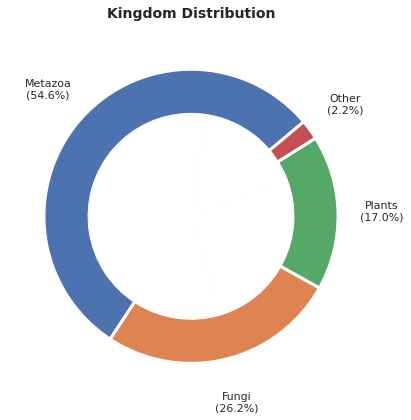

In [35]:
df_postive = df[df['class'] == 1]
df_negative = df[df['class'] == 0]

fig, ax = plt.subplots(figsize=(6, 6))

data = kingdom['counts'].tolist()
labels = kingdom['kingdom'].tolist()
total = sum(data)


formatted_labels = [f"{lbl}\n({val/total*100:.1f}%)" for lbl, val in zip(labels, data)]


ax.pie(
    data,
    labels=formatted_labels,       
    labeldistance=1.3,           
    startangle=40,                
    textprops={'fontsize': 11, 'ha': 'center'},
    wedgeprops={
        'edgecolor': 'white',  
        'linewidth': 3        
    }
)
shadow = ax.pie(data, radius=0.7, colors=['white']*len(data), startangle=90)

ax.set_title("Kingdom Distribution", fontsize=14, weight='bold', pad=15)
plt.tight_layout()
plt.savefig('Kingdom_Distribution.png', format='png', bbox_inches='tight')
plt.show()

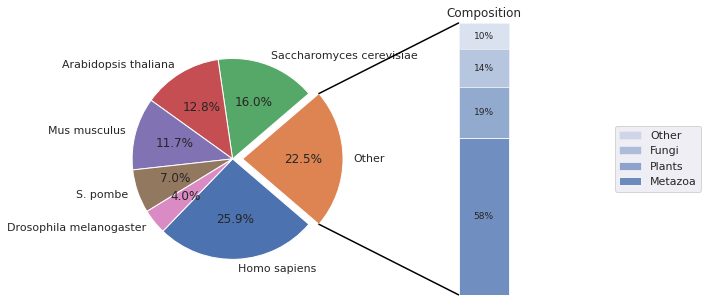

In [36]:


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 5))
fig.subplots_adjust(wspace=0)

data = df['organism_name'].value_counts().tolist()
labels = df['organism_name'].value_counts().index.tolist()
total = sum(data)


target_idx = labels.index('Other') if 'Other' in labels else -1

explode = [0.1 if i == target_idx else 0 for i in range(len(data))]

cum_pct_before = sum(data[:target_idx]) / total
target_wedge_pct = data[target_idx] / total
angle = - (cum_pct_before * 360 + (target_wedge_pct * 360) / 2)

wedges, texts, autotexts = ax1.pie(
    data, 
    autopct='%1.1f%%', 
    startangle=angle,
    labels=labels,
    explode=explode,
)


bar_data = remaining_organisms_grouped['counts'] / remaining_organisms_grouped['counts'].sum()
bar_labels = remaining_organisms_grouped['kingdom'].tolist()
bottom = 1.0
width = 0.2

for j, (height, label) in enumerate(reversed(list(zip(bar_data, bar_labels)))):
    bottom -= height
    bc = ax2.bar(0, height, width, bottom=bottom, color='C0', label=label,
                 alpha=0.2 + 0.2 * (j % 4))
    

    y_pos = bottom + height / 2  
    ax2.text(0, y_pos, f"{height:.0%}", ha='center', va='center', fontsize=9)

ax2.set_title('Composition')
ax2.legend(loc='center left', bbox_to_anchor=(1, 0.5))
ax2.axis('off')
ax2.set_xlim(-2.5 * width, 2.5 * width)
ax2.set_ylim(0, 1)


target_wedge = wedges[target_idx]
theta1, theta2 = target_wedge.theta1, target_wedge.theta2
center, r = target_wedge.center, target_wedge.r
bar_height = sum(bar_data)


x = r * np.cos(np.deg2rad(theta2)) + center[0]
y = r * np.sin(np.deg2rad(theta2)) + center[1]
con = ConnectionPatch(xyA=(-width / 2, bar_height), coordsA=ax2.transData,
                      xyB=(x, y), coordsB=ax1.transData)
con.set_color('black')
con.set_linewidth(1.5)
ax2.add_artist(con)


x = r * np.cos(np.deg2rad(theta1)) + center[0]
y = r * np.sin(np.deg2rad(theta1)) + center[1]
con = ConnectionPatch(xyA=(-width / 2, 0), coordsA=ax2.transData,
                      xyB=(x, y), coordsB=ax1.transData)
con.set_color('black')
con.set_linewidth(1.5)
ax2.add_artist(con)
plt.savefig('Species.png', format='png', bbox_inches='tight')
plt.show()

In [37]:
seaborn.set_theme()
seaborn.set_theme(
context='notebook',
style='darkgrid',
palette='deep',
font='sans-serif',
font_scale=1,
color_codes=True,
rc=None
)

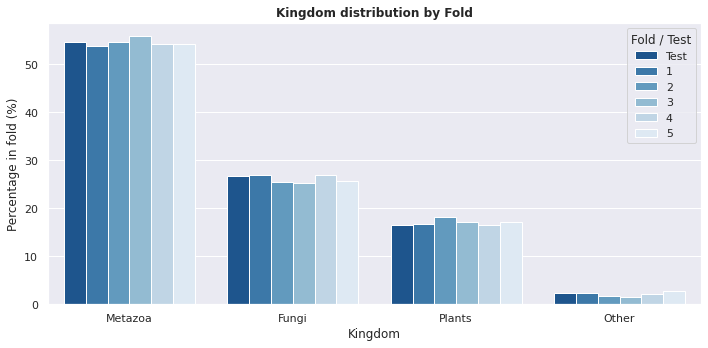

In [38]:


df_pct = (
    df.groupby('fold')['kingdom']
    .value_counts(normalize=True)
    .mul(100)
    .rename('percent')
    .reset_index()
)
df_pct['fold'] = df_pct['fold'].replace({-1: 'Test'})

plt.figure(figsize=(10, 5))
seaborn.barplot(data=df_pct, x='kingdom', y='percent', hue='fold', palette='Blues_r')

plt.title("Kingdom distribution by Fold", weight='bold')
plt.ylabel("Percentage in fold (%)")
plt.xlabel("Kingdom")
plt.legend(title="Fold / Test")
plt.tight_layout()
plt.savefig('Kingdom_Percentages_by_Fold.png', format='png', bbox_inches='tight')
plt.show()

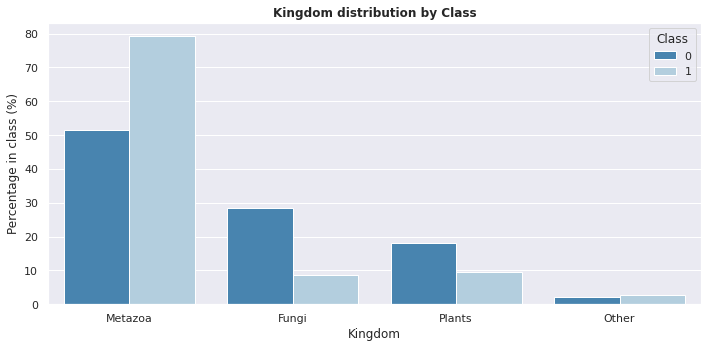

In [39]:

df_PvN_K = (
    df.groupby('class')['kingdom']
    .value_counts(normalize=True)
    .mul(100)
    .rename('percent')
    .reset_index()
)


plt.figure(figsize=(10, 5))
seaborn.barplot(data=df_PvN_K, x='kingdom', y='percent', hue='class', palette='Blues_r')

plt.title("Kingdom distribution by Class", weight='bold')
plt.ylabel("Percentage in class (%)")
plt.xlabel("Kingdom")
plt.legend(title="Class")
plt.tight_layout()
plt.savefig('Kingdom_Percentages_by_Class.png', format='png', bbox_inches='tight')
plt.show()

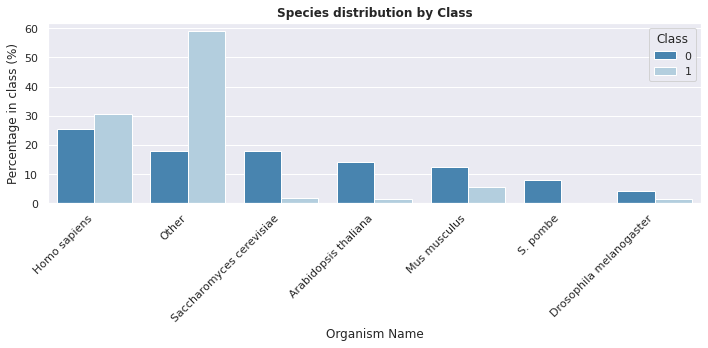

In [40]:

df_PvN_S = (
    df.groupby('class')['organism_name']
    .value_counts(normalize=True)
    .mul(100)
    .rename('percent')
    .reset_index()
)


plt.figure(figsize=(10, 5))
seaborn.barplot(data=df_PvN_S, x='organism_name', y='percent', hue='class', palette='Blues_r')

plt.title("Species distribution by Class", weight='bold')
plt.ylabel("Percentage in class (%)")
plt.xlabel("Organism Name")

# Rotate the tick labels:
plt.xticks(rotation=45, ha='right')

plt.legend(title="Class")
plt.tight_layout()
plt.savefig('Species_Percentages_by_Class.png', format='png', bbox_inches='tight')
plt.show()